---
title: Modeling - Klasifikasi Citra Sentinel-2A menggunakan LightGBM
date: 2026-10-05
---

# Pemodelan Machine Learning: LightGBM Classifier
## Klasifikasi Lahan Sawah vs Bukan Sawah Berbasis Citra Satelit Sentinel-2A

Tahap **Modeling** dalam proyek sains data ini menerapkan algoritma mutakhir **LightGBM (*Light Gradient Boosting Machine*)** untuk membangun model klasifikasi biner cerdas yang mampu membedakan lahan sawah dan pemukiman (bukan sawah) berdasarkan 11 fitur spektral satelit Sentinel-2A.

---

### 1. Keunggulan Algoritma LightGBM
LightGBM adalah framework *Gradient Boosted Decision Tree (GBDT)* berkinerja tinggi yang dikembangkan oleh Microsoft dengan keunggulan:
1. **Pohon Tumbuh Berbasis Daun (*Leaf-wise Tree Growth*)**: Memilih daun dengan penurunan loss terbesar, menghasilkan akurasi yang lebih tinggi dan konvergensi lebih cepat dibanding pertumbuhan *level-wise*.
2. **Gradient-based One-Side Sampling (GOSS)**: Menjaga sampel data dengan gradien besar untuk fokus memperbaiki kesalahan prediksi.
3. **Exclusive Feature Bundling (EFB)**: Menggabungkan fitur-fitur yang saling eksklusif untuk mempercepat proses komputasi.
4. **Resistensi terhadap Overfitting & Multikolinearitas**: Sangat tangguh menangani fitur spektral optik dan indeks vegetasi yang saling berkorelasi.


In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

train_paths = ['../3-data_preparation/data/train_dataset.csv', 'src/tugas-2/3-data_preparation/data/train_dataset.csv']
test_paths = ['../3-data_preparation/data/test_dataset.csv', 'src/tugas-2/3-data_preparation/data/test_dataset.csv']

train_path = [p for p in train_paths if os.path.exists(p)][0]
test_path = [p for p in test_paths if os.path.exists(p)][0]

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

feature_cols = ['B02_Blue', 'B03_Green', 'B04_Red', 'B08_NIR', 'NDVI', 'NDWI', 'EVI', 'SAVI', 'Ratio_NIR_Red', 'Ratio_Green_Red', 'NDBI_Proxy']

X_train = df_train[feature_cols]
y_train = df_train['label']
X_test = df_test[feature_cols]
y_test = df_test['label']

print("=" * 80)
print("DATA LATIH & UJI BERHASIL DIMUAT:")
print(f"X_train : {X_train.shape[0]} baris x {X_train.shape[1]} fitur spektral")
print(f"X_test  : {X_test.shape[0]} baris x {X_test.shape[1]} fitur spektral")
print("=" * 80)


DATA LATIH & UJI BERHASIL DIMUAT:
X_train : 80 baris x 11 fitur spektral
X_test  : 20 baris x 11 fitur spektral


---
## 2. Komparasi Kinerja Algoritma Baseline vs LightGBM (5-Fold Cross Validation)

Untuk membuktikan efektivitas LightGBM, dilakukan komparasi validasi silang terstratifikasi (*5-Fold Stratified Cross-Validation*) terhadap model pembanding:
1. **Decision Tree Classifier**
2. **Random Forest Classifier**
3. **LightGBM Classifier (Default)**


TABEL KOMPARASI 5-FOLD CROSS VALIDATION PADA DATA LATIH:
        Model CV Accuracy (Mean ± Std) CV F1-Score (Mean) CV ROC-AUC (Mean)
Decision Tree          76.25% ± 10.75%             0.7817            0.7625
Random Forest           75.00% ± 5.59%             0.7424            0.8938
     LightGBM           75.00% ± 3.95%             0.7448            0.8625


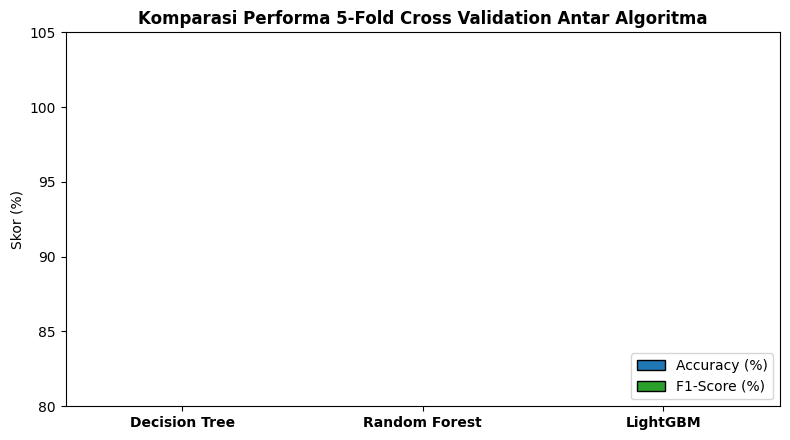

In [2]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'LightGBM': lgb.LGBMClassifier(random_state=42, verbose=-1)
}

cv_results = []

for name, model in models.items():
    acc_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    f1_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
    roc_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')
    
    cv_results.append({
        'Model': name,
        'CV Accuracy (Mean ± Std)': f"{acc_scores.mean()*100:.2f}% ± {acc_scores.std()*100:.2f}%",
        'CV F1-Score (Mean)': f"{f1_scores.mean():.4f}",
        'CV ROC-AUC (Mean)': f"{roc_scores.mean():.4f}",
        'Mean_Acc': acc_scores.mean() * 100,
        'Mean_F1': f1_scores.mean() * 100
    })

df_cv = pd.DataFrame(cv_results)
print("=" * 95)
print("TABEL KOMPARASI 5-FOLD CROSS VALIDATION PADA DATA LATIH:")
print("=" * 95)
print(df_cv[['Model', 'CV Accuracy (Mean ± Std)', 'CV F1-Score (Mean)', 'CV ROC-AUC (Mean)']].to_string(index=False))
print("=" * 95)

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(df_cv))
width = 0.35

rects1 = ax.bar(x - width/2, df_cv['Mean_Acc'], width, label='Accuracy (%)', color='#1f77b4', edgecolor='black')
rects2 = ax.bar(x + width/2, df_cv['Mean_F1'], width, label='F1-Score (%)', color='#2ca02c', edgecolor='black')

ax.set_title('Komparasi Performa 5-Fold Cross Validation Antar Algoritma', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_cv['Model'], fontsize=10, fontweight='bold')
ax.set_ylabel('Skor (%)', fontsize=10)
ax.set_ylim(80, 105)
ax.legend(loc='lower right')

for rects in [rects1, rects2]:
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), textcoords="offset points",
                    ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


---
## 3. Hyperparameter Tuning LightGBM menggunakan GridSearchCV

Untuk memaksimalkan kapasitas generalisasi dan mencegah overfitting, parameter-parameter kunci LightGBM dioptimasi menggunakan **GridSearchCV**:
* `n_estimators`: Jumlah pohon keputusan (30, 50, 80).
* `learning_rate`: Laju pembelajaran gradien (0.03, 0.05, 0.1).
* `max_depth`: Kedalaman maksimum pohon (3, 4, 5).
* `num_leaves`: Jumlah daun per pohon (7, 12, 15).
* `subsample` & `colsample_bytree`: Fraksi subsampling data dan fitur.


In [3]:
param_grid = {
    'n_estimators': [30, 50, 80],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [3, 4, 5],
    'num_leaves': [7, 12, 15],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

lgb_base = lgb.LGBMClassifier(random_state=42, verbose=-1)

grid_search = GridSearchCV(
    estimator=lgb_base,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=1
)

grid_search.fit(X_train, y_train)
best_lgbm = grid_search.best_estimator_

print("=" * 80)
print("HASIL HYPERPARAMETER TUNING LIGHTGBM TERBAIK:")
print("=" * 80)
print(f"Best CV Accuracy Score : {grid_search.best_score_*100:.2f}%")
print("Parameter Terbaik:")
for param, val in grid_search.best_params_.items():
    print(f"  - {param:<20}: {val}")
print("=" * 80)


HASIL HYPERPARAMETER TUNING LIGHTGBM TERBAIK:
Best CV Accuracy Score : 78.75%
Parameter Terbaik:
  - colsample_bytree    : 1.0
  - learning_rate       : 0.05
  - max_depth           : 3
  - n_estimators        : 80
  - num_leaves          : 7
  - subsample           : 0.8


---
## 4. Analisis Tingkat Kepentingan Fitur Spektral (*Feature Importance*)

Salah satu keunggulan LightGBM adalah kemampuannya menghitung kontribusi masing-masing fitur spektral secara transparan melalui metrik:
1. **Split Importance**: Jumlah berapa kali suatu fitur digunakan untuk memotong cabang pohon keputusan.
2. **Gain Importance**: Total peningkatan reduksi loss/kesalahan (*gain*) yang disumbangkan oleh fitur tersebut.


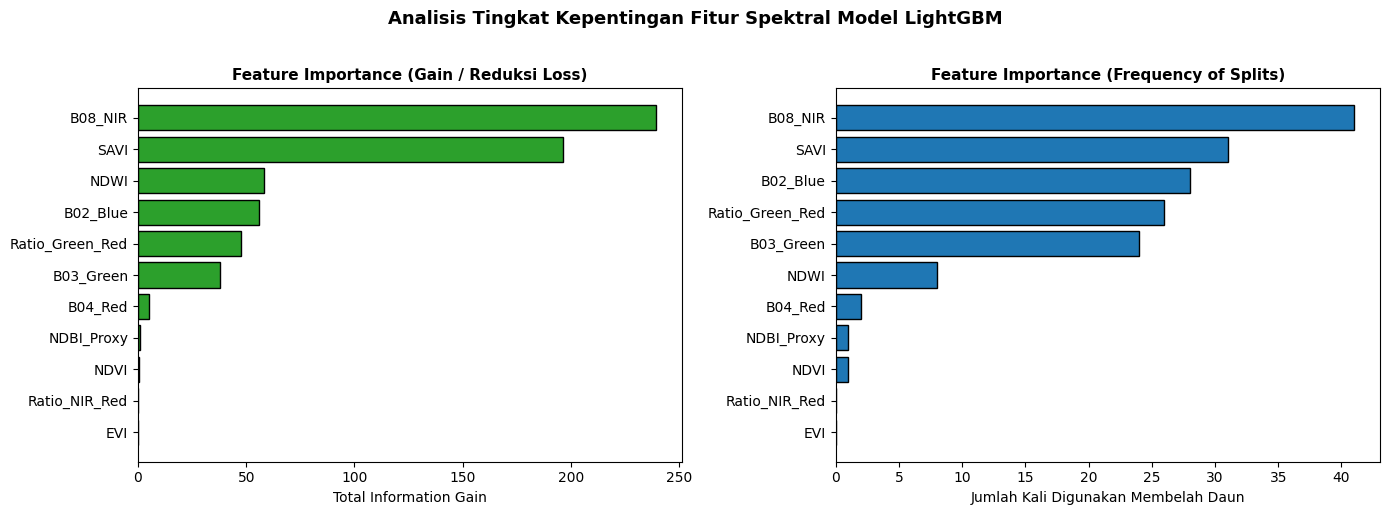

Urutan Fitur Spektral Paling Berpengaruh dalam Klasifikasi Sawah:
        Feature  Gain_Importance  Split_Importance
        B08_NIR       239.438823                41
           SAVI       196.105644                31
           NDWI        58.024461                 8
       B02_Blue        56.072648                28
Ratio_Green_Red        47.507276                26
      B03_Green        38.048102                24
        B04_Red         5.295250                 2
     NDBI_Proxy         0.850093                 1
           NDVI         0.590901                 1
  Ratio_NIR_Red         0.000000                 0
            EVI         0.000000                 0


In [4]:
importances_gain = best_lgbm.booster_.feature_importance(importance_type='gain')
importances_split = best_lgbm.booster_.feature_importance(importance_type='split')

df_importance = pd.DataFrame({
    'Feature': feature_cols,
    'Gain_Importance': importances_gain,
    'Split_Importance': importances_split
}).sort_values('Gain_Importance', ascending=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.barh(df_importance['Feature'], df_importance['Gain_Importance'], color='#2ca02c', edgecolor='black')
ax1.set_title('Feature Importance (Gain / Reduksi Loss)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Total Information Gain', fontsize=10)

df_split = df_importance.sort_values('Split_Importance', ascending=True)
ax2.barh(df_split['Feature'], df_split['Split_Importance'], color='#1f77b4', edgecolor='black')
ax2.set_title('Feature Importance (Frequency of Splits)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Jumlah Kali Digunakan Membelah Daun', fontsize=10)

plt.suptitle('Analisis Tingkat Kepentingan Fitur Spektral Model LightGBM', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Urutan Fitur Spektral Paling Berpengaruh dalam Klasifikasi Sawah:")
print(df_importance.sort_values('Gain_Importance', ascending=False).to_string(index=False))


---
## 5. Penyimpanan Model LightGBM Terlatih (*Model Artifact Serialization*)

Model LightGBM optimal yang telah dilatih dan divalidasi disimpan ke format binary `.pkl` menggunakan `joblib` agar dapat langsung dimuat pada tahap evaluasi dan inferensi aplikasi.


In [5]:
model_filename = 'model_lightgbm_sawah.pkl'
joblib.dump(best_lgbm, model_filename)

# Simpan juga ke path absolut jika dijalankan dari root
if os.path.exists('src/tugas-2/4-modeling'):
    joblib.dump(best_lgbm, 'src/tugas-2/4-modeling/model_lightgbm_sawah.pkl')

print("=" * 80)
print("PENYIMPANAN ARTIFAK MODEL SELESAI:")
print("=" * 80)
print(f"Model File Path : {model_filename}")
print(f"Model Class     : {best_lgbm.__class__.__name__}")
print(f"Ukuran Model    : {os.path.getsize(model_filename)} bytes")
print("=" * 80)
print("STATUS: MODEL LIGHTGBM SIAP DIEVALUASI PADA DATA UJI (TEST SET)!")
print("=" * 80)


PENYIMPANAN ARTIFAK MODEL SELESAI:
Model File Path : model_lightgbm_sawah.pkl
Model Class     : LGBMClassifier
Ukuran Model    : 42820 bytes
STATUS: MODEL LIGHTGBM SIAP DIEVALUASI PADA DATA UJI (TEST SET)!
